# 3. Experimentos y resultados

**Proyecto Integrador · Métodos Numéricos · Segunda entrega**
David Castro, Alejandro Pardo, Tomás Rincón · Docente: Edwin Fernando Muñoz
Artículo base: Cartis & Roberts (2019), *A derivative-free Gauss–Newton method*.

Genera todas las tablas y figuras del informe y las guarda en `resultados/` y `figuras/`. Tarda unos minutos.

El cuaderno es autónomo: basta con ejecutar todas las celdas en Colab o Jupyter.

In [1]:
import time, csv
from dataclasses import dataclass
from pathlib import Path
from typing import Callable
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import least_squares  # solo validación y f* de referencia

## Código de apoyo

Copia de lo explicado en los cuadernos 1 y 2, para que este cuaderno funcione sin otros archivos.

In [2]:
def eliminacion_gauss(A, B):
    """Eliminación hacia adelante con pivoteo parcial.

    A es n x n; B es n x p (p lados derechos). Con una sola eliminación se
    resuelven los p sistemas, que es la misma ventaja que tiene LU (Quiz 3, 2g).
    El multiplicador es m = a_ji / a_ii y la actualización a_jk := a_jk - m a_ik.

    Devuelve U, B modificada y razon_pivotes = min|u_ii| / max|u_ii|. Si la razón
    es casi cero, A está cerca de ser singular.
    """
    U = np.array(A, dtype=float)
    C = np.array(B, dtype=float)
    n = U.shape[0]
    for i in range(n - 1):
        # Pivoteo parcial: se sube la fila con el mayor |a_ji| para que |m| <= 1
        # y los errores de redondeo no se amplifiquen.
        p = i + int(np.argmax(np.abs(U[i:, i])))
        if U[p, i] == 0.0:
            raise np.linalg.LinAlgError("Matriz singular en la eliminación de Gauss.")
        if p != i:
            U[[i, p]] = U[[p, i]]
            C[[i, p]] = C[[p, i]]
        for j in range(i + 1, n):
            m = U[j, i] / U[i, i]
            U[j, i] = 0.0
            U[j, i + 1:] -= m * U[i, i + 1:]
            C[j] -= m * C[i]
    pivotes = np.abs(np.diag(U))
    razon = pivotes.min() / pivotes.max() if pivotes.max() > 0 else 0.0
    return U, C, razon


def sustitucion_atras(U, c):
    """Resuelve Ux = c con U triangular superior. c puede tener varias columnas."""
    n = U.shape[0]
    x = np.array(c, dtype=float)
    for i in range(n - 1, -1, -1):
        if U[i, i] == 0.0:
            raise np.linalg.LinAlgError("Pivote nulo en la sustitución hacia atrás.")
        x[i] = (x[i] - U[i, i + 1:] @ x[i + 1:]) / U[i, i]
    return x


def resolver_gauss(A, B):
    """Resuelve AX = B. Devuelve X y la razón de pivotes."""
    U, C, razon = eliminacion_gauss(A, B)
    return sustitucion_atras(U, C), razon


def gram_schmidt_modificado(A, tol=1e-13):
    """QR reducida A = QR (m >= n), igual al notebook de la Semana 6.

    Cada columna v_j se actualiza justo después de cada proyección:
    v_j := v_j - r_ij q_i. tol es relativa a la mayor columna de A.
    """
    V = np.array(A, dtype=float)
    m, n = V.shape
    if m < n:
        raise ValueError("Se requiere m >= n.")
    Q = np.zeros((m, n))
    R = np.zeros((n, n))
    escala = max(np.linalg.norm(V, axis=0).max(), 1e-300)
    for i in range(n):
        R[i, i] = np.linalg.norm(V[:, i])
        if R[i, i] <= tol * escala:
            raise np.linalg.LinAlgError("Columnas linealmente dependientes.")
        Q[:, i] = V[:, i] / R[i, i]
        for j in range(i + 1, n):
            R[i, j] = Q[:, i] @ V[:, j]
            V[:, j] -= R[i, j] * Q[:, i]
    return Q, R


def minimos_cuadrados_qr(A, b):
    """Solución de min ||Ax - b||_2 mediante Rx = Q^T b (Sesión 12).

    Q^T b se calcula proyectando b de forma secuencial, con la misma idea de
    Gram-Schmidt modificado; así se conserva mejor la precisión si Q pierde
    algo de ortogonalidad.
    """
    Q, R = gram_schmidt_modificado(A)
    v = np.array(b, dtype=float)
    c = np.zeros(R.shape[0])
    for i in range(R.shape[0]):
        c[i] = Q[:, i] @ v
        v -= c[i] * Q[:, i]
    return sustitucion_atras(R, c)

In [3]:
@dataclass
class Problema:
    numero: int            # número en la Tabla 2
    nombre: str
    r: Callable            # residuos, R^n -> R^m
    J: Callable            # Jacobiano analítico, m x n
    x0: np.ndarray
    dos_f0_tabla: float
    dos_f_estrella: float

    @property
    def f_estrella(self):
        return self.dos_f_estrella / 2

    @property
    def n(self):
        return len(self.x0)

    @property
    def m(self):
        return len(self.r(self.x0))


def _rosenbrock_r(x):
    return np.array([10 * (x[1] - x[0] ** 2), 1 - x[0]])


def _rosenbrock_J(x):
    return np.array([[-20 * x[0], 10.0], [-1.0, 0.0]])


def _freudenstein_r(x):
    return np.array([-13 + x[0] + ((5 - x[1]) * x[1] - 2) * x[1],
                     -29 + x[0] + ((x[1] + 1) * x[1] - 14) * x[1]])


def _freudenstein_J(x):
    return np.array([[1.0, 10 * x[1] - 3 * x[1] ** 2 - 2],
                     [1.0, 3 * x[1] ** 2 + 2 * x[1] - 14]])


def _theta(x):
    t = np.arctan(x[1] / x[0]) / (2 * np.pi) if x[0] != 0 else 0.25
    return t + 0.5 if x[0] < 0 else t


def _helical_r(x):
    return np.array([10 * (x[2] - 10 * _theta(x)),
                     10 * (np.hypot(x[0], x[1]) - 1), x[2]])


def _helical_J(x):
    d2 = x[0] ** 2 + x[1] ** 2
    d = np.sqrt(d2)
    return np.array([[100 * x[1] / (2 * np.pi * d2), -100 * x[0] / (2 * np.pi * d2), 10.0],
                     [10 * x[0] / d, 10 * x[1] / d, 0.0],
                     [0.0, 0.0, 1.0]])


_BARD_Y = np.array([0.14, 0.18, 0.22, 0.25, 0.29, 0.32, 0.35, 0.39, 0.37, 0.58,
                    0.73, 0.96, 1.34, 2.10, 4.39])
_BARD_U = np.arange(1.0, 16.0)
_BARD_V = 16.0 - _BARD_U
_BARD_W = np.minimum(_BARD_U, _BARD_V)


def _bard_r(x):
    return _BARD_Y - (x[0] + _BARD_U / (_BARD_V * x[1] + _BARD_W * x[2]))


def _bard_J(x):
    d = (_BARD_V * x[1] + _BARD_W * x[2]) ** 2
    return np.column_stack((-np.ones(15), _BARD_U * _BARD_V / d, _BARD_U * _BARD_W / d))


def _powell_r(x):
    return np.array([x[0] + 10 * x[1], np.sqrt(5) * (x[2] - x[3]),
                     (x[1] - 2 * x[2]) ** 2, np.sqrt(10) * (x[0] - x[3]) ** 2])


def _powell_J(x):
    a = 2 * (x[1] - 2 * x[2])
    b = 2 * np.sqrt(10) * (x[0] - x[3])
    s = np.sqrt(5)
    return np.array([[1.0, 10.0, 0.0, 0.0], [0.0, 0.0, s, -s],
                     [0.0, a, -2 * a, 0.0], [b, 0.0, 0.0, -b]])


_KO_Y = np.array([0.1957, 0.1947, 0.1735, 0.1600, 0.0844, 0.0627, 0.0456,
                  0.0342, 0.0323, 0.0235, 0.0246])
_KO_U = np.array([4.0, 2.0, 1.0, 0.5, 0.25, 0.1670, 0.1250, 0.1000, 0.0833,
                  0.0714, 0.0625])


def _kowalik_r(x):
    u = _KO_U
    return _KO_Y - x[0] * (u ** 2 + u * x[1]) / (u ** 2 + u * x[2] + x[3])


def _kowalik_J(x):
    u = _KO_U
    num = u ** 2 + u * x[1]
    den = u ** 2 + u * x[2] + x[3]
    return np.column_stack((-num / den, -x[0] * u / den,
                            x[0] * num * u / den ** 2, x[0] * num / den ** 2))


def _watson_r(x):
    n = len(x)
    t = np.arange(1, 30) / 29.0
    pot = np.vander(t, n, increasing=True)            # t^(j-1), j = 1..n
    suma = pot @ x
    deriv = pot[:, :-1] @ (np.arange(1, n) * x[1:])   # suma de (j-1) x_j t^(j-2)
    return np.concatenate((deriv - suma ** 2 - 1, [x[0], x[1] - x[0] ** 2 - 1]))


def _watson_J(x):
    n = len(x)
    t = np.arange(1, 30) / 29.0
    pot = np.vander(t, n, increasing=True)
    suma = pot @ x
    J = np.zeros((31, n))
    J[:29, 0] = -2 * suma
    J[:29, 1:] = pot[:, :-1] * np.arange(1, n) - 2 * suma[:, None] * pot[:, 1:]
    J[29, 0] = 1.0
    J[30, 0] = -2 * x[0]
    J[30, 1] = 1.0
    return J


PROBLEMAS = [
    Problema(7, "Rosenbrock", _rosenbrock_r, _rosenbrock_J, np.array([-1.2, 1.0]), 24.2, 0.0),
    Problema(13, "Freudenstein & Roth", _freudenstein_r, _freudenstein_J,
             np.array([0.5, -2.0]), 400.5, 48.98425),
    Problema(9, "Helical Valley", _helical_r, _helical_J, np.array([-1.0, 0.0, 0.0]), 2500.0, 0.0),
    Problema(15, "Bard", _bard_r, _bard_J, np.array([1.0, 1.0, 1.0]), 41.68170, 8.214877e-3),
    Problema(11, "Powell Singular", _powell_r, _powell_J,
             np.array([3.0, -1.0, 0.0, 1.0]), 215.0, 0.0),
    Problema(17, "Kowalik & Osborne", _kowalik_r, _kowalik_J,
             np.array([0.25, 0.39, 0.415, 0.39]), 5.313172e-3, 3.075056e-4),
    Problema(19, "Watson", _watson_r, _watson_J, 0.5 * np.ones(6), 16.43083, 2.287670e-3),
]


class Evaluador:
    """Envuelve r(x): cuenta evaluaciones y, si se pide, agrega ruido (sección 5.2 del artículo).

    ruido = None, 'multiplicativo' (r_i (1 + e)) o 'aditivo' (r_i + e), con
    e ~ N(0, sigma^2) independiente por componente y por evaluación.
    """

    def __init__(self, problema, ruido=None, sigma=1e-2, semilla=None):
        self.problema = problema
        self.ruido = ruido
        self.sigma = sigma
        self.rng = np.random.default_rng(semilla)
        self.n_eval = 0
        self.n_eval_J = 0

    def r(self, x):
        self.n_eval += 1
        valor = self.problema.r(x)
        if self.ruido is None:
            return valor
        e = self.rng.normal(0.0, self.sigma, valor.shape)
        return valor * (1 + e) if self.ruido == "multiplicativo" else valor + e

    def J(self, x):
        self.n_eval_J += 1
        return self.problema.J(x)

    def f_real(self, x):
        """f sin ruido y sin contar: solo para medir, nunca la usa el algoritmo."""
        return 0.5 * float(np.sum(self.problema.r(x) ** 2))

In [4]:
ETA1, ETA2 = 0.1, 0.7          # umbrales de aceptación
GAMMA_DEC, GAMMA_INC = 0.5, 2.0
DELTA_MAX = 1e10
DELTA_FIN = 1e-10
RAZON_MIN = 1e-8               # geometría: razón de pivotes mínima de W/Delta


def radio_inicial(x0):
    """Delta_0 = 0.1 max(||x0||_inf, 1), como en la sección 5.1 del artículo."""
    return 0.1 * max(np.linalg.norm(x0, np.inf), 1.0)


def paso_cauchy(g, H, delta):
    """Minimiza el modelo sobre -g dentro de la región: s = -t g.

    Es descenso del gradiente con la tasa óptima para el modelo cuadrático:
    t = g'g / g'Hg, recortada a delta / ||g||.
    """
    norma_g = np.linalg.norm(g)
    curvatura = g @ H @ g
    t_borde = delta / norma_g
    t = min(norma_g ** 2 / curvatura, t_borde) if curvatura > 0 else t_borde
    return -t * g


def valor_modelo(g, H, s):
    """Cambio del modelo m(s) - m(0) = g's + 1/2 s'Hs (ec. 2.5)."""
    return g @ s + 0.5 * s @ H @ s


def paso_gn_qr(J, r, g, H, delta):
    """Paso de Gauss-Newton: min ||J s + r|| por QR, recortado al radio delta.

    Si J está casi singular, el paso recortado puede bajar el modelo menos que el
    de Cauchy e incumplir la condición 2.8 del artículo, que sostiene la
    convergencia global. Por eso se devuelve el mejor de los dos según el modelo.
    """
    cauchy = paso_cauchy(g, H, delta)
    try:
        s = minimos_cuadrados_qr(J, -r)
    except np.linalg.LinAlgError:
        return cauchy
    norma = np.linalg.norm(s)
    if norma > delta:
        s = s * (delta / norma)
    return s if valor_modelo(g, H, s) <= valor_modelo(g, H, cauchy) else cauchy


class JacobianoExacto:
    def __init__(self, ev, x, rx, delta):
        self.ev = ev
        self.J = ev.J(x)

    def tras_paso(self, x_nuevo, r_nuevo, aceptado, x, rx, delta):
        if aceptado:
            self.J = self.ev.J(x_nuevo)


class JacobianoDiferencias:
    """Diferencias finitas hacia adelante (Unidad 2): n evaluaciones por Jacobiano."""
    H_BASE = np.sqrt(np.finfo(float).eps)   # paso óptimo aprox. sqrt(épsilon), Unidad 1

    def __init__(self, ev, x, rx, delta):
        self.ev = ev
        self.J = self._calcular(x, rx)

    def _calcular(self, x, rx):
        J = np.zeros((len(rx), len(x)))
        for j in range(len(x)):
            h = self.H_BASE * max(1.0, abs(x[j]))
            y = x.copy()
            y[j] += h
            J[:, j] = (self.ev.r(y) - rx) / h
        return J

    def tras_paso(self, x_nuevo, r_nuevo, aceptado, x, rx, delta):
        if aceptado:
            self.J = self._calcular(x_nuevo, r_nuevo)


class JacobianoInterpolacion:
    """Jacobiano de DFO-GN: interpolación lineal con n+1 puntos (ec. 2.2 a 2.4).

    Por cada residuo r_i se pide m_i(y_t - x) = r_i(y_t). Con W de filas (y_t - x)'
    y D de filas r(y_t) - r(x), eso equivale a W J' = D, que se resuelve con una
    sola eliminación de Gauss para los m residuos.
    """

    def __init__(self, ev, x, rx, delta):
        self.ev = ev
        self._reconstruir(x, delta)
        self._ajustar(x, rx, delta)

    def _reconstruir(self, x, delta):
        """Y = {x + delta e_j}: base canónica, la geometría ideal. Cuesta n evaluaciones."""
        self.Y = [x + delta * e for e in np.eye(len(x))]
        self.rY = [self.ev.r(y) for y in self.Y]

    def _sistema(self, x, rx, delta):
        W = np.array([y - x for y in self.Y]) / delta   # se escala para medir solo la forma
        D = np.array([ry - rx for ry in self.rY]) / delta
        return resolver_gauss(W, D)

    def _ajustar(self, x, rx, delta):
        try:
            Jt, razon = self._sistema(x, rx, delta)
        except np.linalg.LinAlgError:
            razon = 0.0
        if razon < RAZON_MIN:              # puntos casi alineados: geometría degenerada
            self._reconstruir(x, delta)
            Jt, razon = self._sistema(x, rx, delta)
        self.J = Jt.T

    def tras_paso(self, x_nuevo, r_nuevo, aceptado, x, rx, delta):
        """Entra el punto de prueba y sale el más lejano del centro de la región."""
        centro, r_centro = (x_nuevo, r_nuevo) if aceptado else (x, rx)
        puntos = self.Y + [x if aceptado else x_nuevo]
        valores = self.rY + [rx if aceptado else r_nuevo]
        distancias = [np.linalg.norm(p - centro) for p in puntos]
        sale = int(np.argmax(distancias))
        del puntos[sale], valores[sale]
        self.Y, self.rY = puntos, valores
        # Tras un rechazo, si los puntos quedaron lejos el modelo ya no representa
        # la región; se reconstruye en vez de seguir encogiendo el radio.
        if not aceptado and max(np.linalg.norm(p - centro) for p in self.Y) > 2 * delta:
            self._reconstruir(centro, delta)
        self._ajustar(centro, r_centro, delta)


def region_confianza(ev, tipo_J, tipo_paso, presupuesto=None):
    """Región de confianza con cociente R_k (ec. 2.6 y 2.7, regla simplificada 2.15)."""
    inicio = time.perf_counter()
    x = ev.problema.x0.astype(float).copy()
    n = len(x)
    presupuesto = presupuesto or 200 * (n + 1)
    delta = radio_inicial(x)
    rx = ev.r(x)
    fx = 0.5 * rx @ rx
    f0 = fx
    clases = {"interpolacion": JacobianoInterpolacion, "exacto": JacobianoExacto,
              "diferencias": JacobianoDiferencias}
    modelo = clases[tipo_J](ev, x, rx, delta)
    calcular_paso = paso_cauchy if tipo_paso == "cauchy" else None
    historial = [(ev.n_eval, ev.f_real(x), 0)]
    iterados = [x.copy()]
    motivo = "presupuesto"
    k = 0
    while ev.n_eval < presupuesto:
        k += 1
        J = modelo.J
        g = J.T @ rx
        H = J.T @ J
        if fx <= max(1e-12, 1e-20 * f0):
            motivo = "f pequeña"
            break
        if delta < DELTA_FIN:
            motivo = "radio pequeño"
            break
        if np.linalg.norm(g) == 0.0:
            motivo = "gradiente nulo"
            break
        s = calcular_paso(g, H, delta) if calcular_paso else paso_gn_qr(J, rx, g, H, delta)
        x_nuevo = x + s
        r_nuevo = ev.r(x_nuevo)
        f_nuevo = 0.5 * r_nuevo @ r_nuevo
        predicha = -valor_modelo(g, H, s)
        R = (fx - f_nuevo) / predicha if predicha > 0 else -1.0
        if not np.isfinite(R):
            R = -1.0
        aceptado = R >= ETA1
        norma_s = np.linalg.norm(s)
        if R >= ETA2:
            delta = min(max(GAMMA_INC * delta, GAMMA_INC * norma_s), DELTA_MAX)
        elif aceptado:
            delta = max(GAMMA_DEC * delta, norma_s)
        else:
            delta = min(GAMMA_DEC * delta, norma_s)
        modelo.tras_paso(x_nuevo, r_nuevo, aceptado, x, rx, delta)
        if aceptado:
            x, rx, fx = x_nuevo, r_nuevo, f_nuevo
            iterados.append(x.copy())
        historial.append((ev.n_eval, ev.f_real(x), k))
    return {"x": x, "f": ev.f_real(x), "historial": historial, "n_eval": ev.n_eval,
            "n_eval_J": ev.n_eval_J, "n_iter": k, "motivo": motivo, "iterados": iterados,
            "radio_final": delta, "tiempo": time.perf_counter() - inicio}


def descenso_gradiente(ev, eta, presupuesto=None):
    """x := x - eta grad f, con grad f = J'r y tasa fija (Sesión 23)."""
    inicio = time.perf_counter()
    x = ev.problema.x0.astype(float).copy()
    presupuesto = presupuesto or 200 * (len(x) + 1)
    historial = [(0, ev.f_real(x), 0)]
    motivo = "presupuesto"
    k = 0
    while ev.n_eval < presupuesto:
        k += 1
        g = ev.J(x).T @ ev.r(x)
        if not np.isfinite(g).all():
            motivo = "divergió"
            break
        x = x - eta * g
        with np.errstate(all="ignore"):
            f = ev.f_real(x)
        if not np.isfinite(f):
            motivo = "divergió"
            historial.append((ev.n_eval, np.inf, k))
            break
        historial.append((ev.n_eval, f, k))
    return {"x": x, "f": historial[-1][1], "historial": historial, "n_eval": ev.n_eval,
            "n_eval_J": ev.n_eval_J, "n_iter": k, "motivo": motivo,
            "tiempo": time.perf_counter() - inicio}

## 1. Configuración

Semilla fija, tolerancias $\tau$ (ec. 5.1 del artículo), ruido con $\sigma=10^{-2}$ (sección 5.2) y presupuesto de $200(n+1)$ evaluaciones. Con `CORRIDAS` semillas se repite cada experimento con ruido.

In [5]:
SEMILLA = 2026
CORRIDAS = 10
SIGMA = 1e-2
TAUS = [1e-1, 1e-3, 1e-5]
ETAS = [1e-1, 1e-2, 1e-3, 1e-4, 1e-5]
BASE = Path.cwd().parent if Path.cwd().name == "cuadernos" else Path.cwd()
RES = BASE / "resultados"
FIG = BASE / "figuras"

# nombre: (origen de J, tipo de paso). El descenso del gradiente se agrega aparte.
METODOS = {
    "DFO-GN Cauchy": ("interpolacion", "cauchy"),
    "DFO-GN QR": ("interpolacion", "qr"),
    "GN exacto QR": ("exacto", "qr"),
    "GN exacto Cauchy": ("exacto", "cauchy"),
    "GN dif. finitas QR": ("diferencias", "qr"),
}
DG = "Descenso gradiente"
COLORES = {"DFO-GN Cauchy": "#2a78d6", "DFO-GN QR": "#1baf7a", "GN exacto QR": "#eda100",
           "GN exacto Cauchy": "#008300", "GN dif. finitas QR": "#4a3aa8", DG: "#e34948"}
MARCAS = {"DFO-GN Cauchy": "o", "DFO-GN QR": "s", "GN exacto QR": "^",
          "GN exacto Cauchy": "v", "GN dif. finitas QR": "D", DG: "X"}

## 2. Funciones de medición y figuras

In [6]:
def correr(nombre, p, eta=None, ruido=None, semilla=None):
    ev = Evaluador(p, ruido=ruido, sigma=SIGMA, semilla=semilla)
    if nombre == DG:
        return descenso_gradiente(ev, eta)
    return region_confianza(ev, *METODOS[nombre])


def n_p(res, p, tau):
    """Ec. 5.1: primera evaluación con f(x_k) <= f* + tau (f(x0) - f*)."""
    f0 = res["historial"][0][1]
    meta = p.f_estrella + tau * (f0 - p.f_estrella)
    for n_eval, f, _ in res["historial"]:
        if f <= meta:
            return n_eval
    return None


def mejor_eta(p):
    """La tasa fija de mejor f final en la rejilla: favorece al descenso del gradiente."""
    filas = [(descenso_gradiente(Evaluador(p), e)["f"], e) for e in ETAS]
    return min(filas)[1], filas


def orden(res, x_ref):
    """Mediana de p en e_{k+1} = C e_k^p, con e_k = ||x_k - x*||, en la zona asintótica.

    Es el mismo cálculo empírico de orden de la Unidad 4. Se descartan errores
    grandes (fuera de la zona asintótica) y cercanos al redondeo.
    """
    e = [np.linalg.norm(x - x_ref) for x in res["iterados"]]
    e = [v for v in e if 1e-9 < v < 1e-1]
    p = [np.log(e[i + 1] / e[i]) / np.log(e[i] / e[i - 1]) for i in range(1, len(e) - 1)
         if e[i] != e[i - 1]]
    return float(np.median(p)) if len(p) >= 2 else float("nan")


def guardar(nombre, cabecera, filas):
    with open(RES / nombre, "w", newline="", encoding="utf-8") as a:
        w = csv.writer(a)
        w.writerow(cabecera)
        w.writerows(filas)


def figura_convergencia(lisos, refs):
    fig, ejes = plt.subplots(2, 4, figsize=(13, 6.2), sharex=False)
    ejes = ejes.ravel()
    for eje, p in zip(ejes, PROBLEMAS):
        for nombre, res in lisos[p.nombre].items():
            h = np.array(res["historial"])
            brecha = np.maximum(h[:, 1] - refs[p.nombre], 1e-14)
            brecha = np.minimum.accumulate(np.where(np.isfinite(brecha), brecha, np.inf))
            eje.step(h[:, 0], brecha, where="post", color=COLORES[nombre], lw=1.8, label=nombre,
                     marker=MARCAS[nombre], markevery=max(len(h) // 6, 1), ms=5)
        eje.set_yscale("log")
        eje.set_title(f"P{p.numero} {p.nombre} (n={p.n}, m={p.m})", fontsize=10)
        eje.grid(alpha=.25)
        eje.spines[["top", "right"]].set_visible(False)
    ejes[-1].axis("off")
    ejes[-1].legend(*ejes[0].get_legend_handles_labels(), loc="center", frameon=False)
    fig.supxlabel("Evaluaciones de r(x)")
    fig.supylabel("Mejor f(x_k) − f*")
    fig.tight_layout()
    fig.savefig(FIG / "fig1_convergencia.png", dpi=170)
    plt.show()


def figura_ruido(ruidos):
    nombres = ["DFO-GN QR", "GN dif. finitas QR", "GN exacto QR"]
    fig, ejes = plt.subplots(1, 2, figsize=(12, 4.2), sharey=True)
    for eje, tipo in zip(ejes, ["multiplicativo", "aditivo"]):
        for i, nombre in enumerate(nombres):
            for j, p in enumerate(PROBLEMAS):
                datos = np.maximum(ruidos[tipo][p.nombre][nombre], 1e-16)
                pos = j + (i - 1) * 0.27 + np.linspace(-.07, .07, len(datos))
                eje.scatter(pos, datos, s=20, color=COLORES[nombre], marker=MARCAS[nombre],
                            alpha=.75, linewidths=0)
                eje.hlines(np.median(datos), j + (i - 1) * .27 - .12, j + (i - 1) * .27 + .12, color="#0b0b0b", lw=1.5)
            eje.plot([], [], MARCAS[nombre], color=COLORES[nombre], label=nombre)
        eje.set_yscale("log")
        eje.set_xticks(np.arange(len(PROBLEMAS)), [f"P{p.numero}" for p in PROBLEMAS])
        eje.set_title(f"Ruido {tipo}, σ = {SIGMA}", fontsize=10)
        eje.grid(alpha=.25, axis="y")
        eje.spines[["top", "right"]].set_visible(False)
    ejes[0].set_ylabel("f(x_final) − f* (sin ruido)")
    ejes[1].legend(frameon=False, title="Barra negra: mediana de 10 corridas", title_fontsize=8, loc="lower right")
    fig.tight_layout()
    fig.savefig(FIG / "fig2_ruido.png", dpi=170)
    plt.show()

## 3. Ejecución

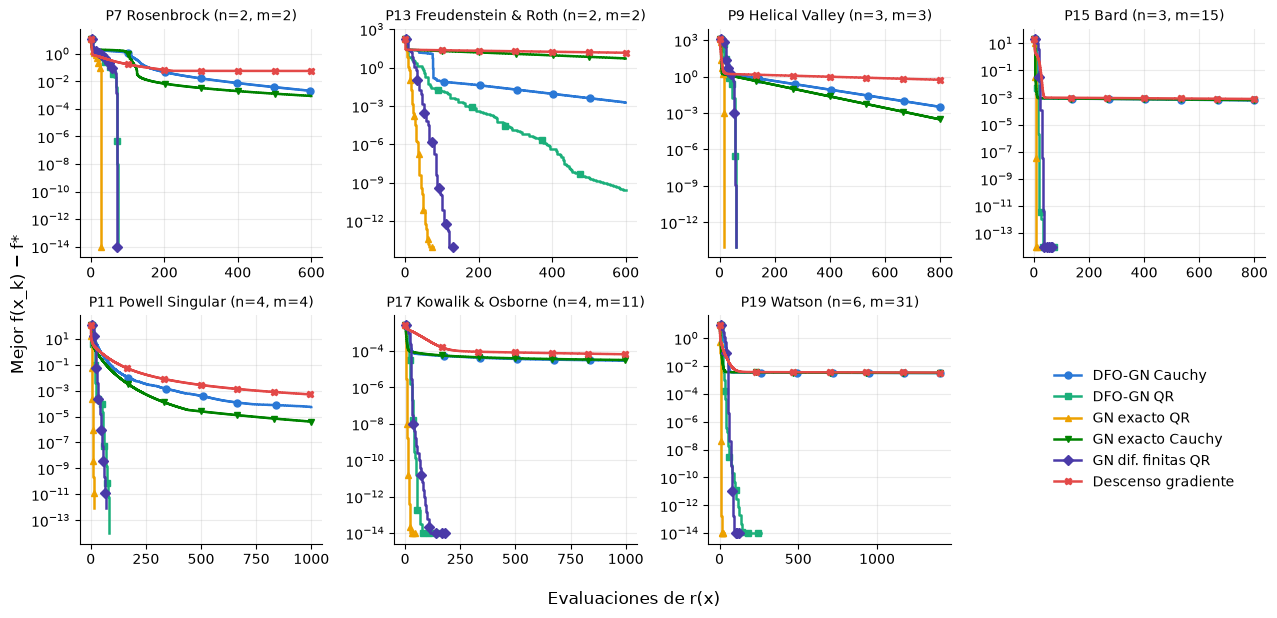

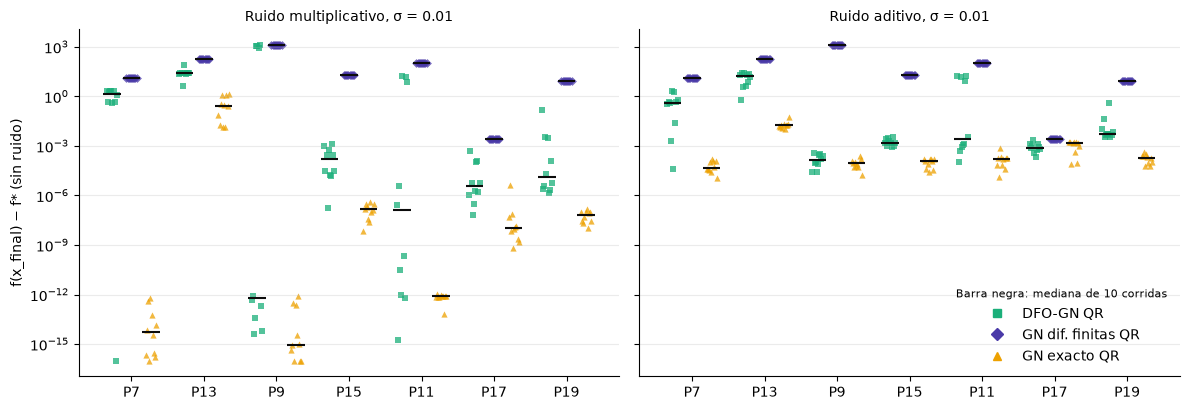

Listo: resultados/ y figuras/ regenerados.


In [7]:
def main():
    RES.mkdir(exist_ok=True)
    FIG.mkdir(exist_ok=True)
    lisos, refs, etas, f_eta, f_e1, f_e4, f_ord = {}, {}, {}, [], [], [], []
    for p in PROBLEMAS:
        ref = least_squares(p.r, p.x0, jac=p.J, xtol=1e-15, ftol=1e-15, gtol=1e-15)
        refs[p.nombre] = ref.cost if p.f_estrella > 0 else 0.0   # f* de la Tabla 2 viene redondeado
        etas[p.nombre], filas = mejor_eta(p)
        f_eta += [[p.nombre, e, f] for f, e in filas]
        lisos[p.nombre] = {}
        for nombre in [*METODOS, DG]:
            res = correr(nombre, p, etas[p.nombre])
            lisos[p.nombre][nombre] = res
            f_e1.append([p.numero, p.nombre, nombre, res["f"], res["n_eval"], res["n_eval_J"],
                         res["n_iter"], res["motivo"]] + [n_p(res, p, t) for t in TAUS])
            tiempos = [correr(nombre, p, etas[p.nombre])["tiempo"] for _ in range(5)]
            f_e4.append([p.nombre, nombre, res["n_iter"], res["n_eval"] / max(res["n_iter"], 1),
                         1e3 * float(np.median(tiempos)) / max(res["n_iter"], 1)])
        x_ref = lisos[p.nombre]["GN exacto QR"]["x"]
        for nombre in ["GN exacto QR", "DFO-GN QR"]:
            f_ord.append([p.nombre, nombre, orden(lisos[p.nombre][nombre], x_ref)])
    guardar("e1_evaluaciones.csv", ["num", "problema", "metodo", "f_final", "n_eval_r", "n_eval_J",
                                    "n_iter", "motivo", "Np_1e-1", "Np_1e-3", "Np_1e-5"], f_e1)
    guardar("e2_orden.csv", ["problema", "metodo", "orden_p"], f_ord)
    guardar("e4_costo.csv", ["problema", "metodo", "n_iter", "eval_r_por_iter", "ms_por_iter"], f_e4)
    guardar("e5_tasa_dg.csv", ["problema", "eta", "f_final"], f_eta)
    figura_convergencia(lisos, refs)

    ruidos, f_e3 = {}, []
    for tipo in ["multiplicativo", "aditivo"]:
        ruidos[tipo] = {}
        for p in PROBLEMAS:
            ruidos[tipo][p.nombre] = {}
            for nombre in [*METODOS, DG]:
                # Misma semilla por corrida: todos los métodos se comparan con igual generador.
                rs = [correr(nombre, p, etas[p.nombre], tipo, SEMILLA + k) for k in range(CORRIDAS)]
                brechas = [r["f"] - refs[p.nombre] for r in rs]
                ruidos[tipo][p.nombre][nombre] = brechas
                exitos = [sum(n_p(r, p, t) is not None for r in rs) for t in TAUS]
                evals = [n_p(r, p, 1e-3) for r in rs if n_p(r, p, 1e-3) is not None]
                f_e3.append([tipo, p.nombre, nombre, *exitos, float(np.median(brechas)),
                             float(np.median(evals)) if evals else None,
                             sum(r["motivo"] == "radio pequeño" for r in rs)])
    guardar("e3_ruido.csv", ["ruido", "problema", "metodo", "exitos_1e-1", "exitos_1e-3", "exitos_1e-5",
                             "mediana_brecha_f", "mediana_Np_1e-3", "corridas_radio_pequeno"], f_e3)
    figura_ruido(ruidos)
    print("Listo: resultados/ y figuras/ regenerados.")


main()

## 4. Sin ruido: evaluaciones para alcanzar $\tau$

Vacío = no alcanzado dentro del presupuesto.

In [8]:
e1 = pd.read_csv(RES / "e1_evaluaciones.csv")
e1

,num,problema,metodo,f_final,n_eval_r,n_eval_J,n_iter,motivo,Np_1e-1,Np_1e-3,Np_1e-5
0,7,Rosenbrock,DFO-GN Cauchy,2.046988e-03,600,0,597,presupuesto,102,337.0,NaN
1,7,Rosenbrock,DFO-GN QR,0.000000e+00,75,0,57,f pequeña,16,68.0,71.0
2,7,Rosenbrock,GN exacto QR,0.000000e+00,29,21,29,f pequeña,9,28.0,29.0
3,7,Rosenbrock,GN exacto Cauchy,8.776833e-04,600,590,599,presupuesto,98,156.0,NaN
4,7,Rosenbrock,GN dif. finitas QR,0.000000e+00,71,0,29,f pequeña,23,68.0,71.0
5,7,Rosenbrock,Descenso gradiente,1.589965e-01,600,600,600,presupuesto,4,NaN,NaN
6,13,Freudenstein & Roth,DFO-GN Cauchy,2.449401e+01,600,0,593,presupuesto,38,77.0,NaN
7,13,Freudenstein & Roth,DFO-GN QR,2.449213e+01,600,0,383,presupuesto,7,62.0,157.0
8,13,Freudenstein & Roth,GN exacto QR,2.449213e+01,76,34,76,radio pequeño,5,12.0,19.0
9,13,Freudenstein & Roth,GN exacto Cauchy,2.975743e+01,600,600,599,presupuesto,149,NaN,NaN


**Lectura:** Cauchy solo alcanza $\tau=10^{-5}$ en 2 de 7 problemas, también con $J$ exacto. El paso limita más que el origen de $J$. DFO-GN QR resuelve los 7.

## 5. Orden de convergencia

$p$ en $e_{k+1}\approx Ce_k^p$, como en la Unidad 4. NaN = muy pocos iterados para estimarlo.

In [9]:
pd.read_csv(RES / "e2_orden.csv")

,problema,metodo,orden_p
0,Rosenbrock,GN exacto QR,NaN
1,Rosenbrock,DFO-GN QR,NaN
2,Freudenstein & Roth,GN exacto QR,0.126309
3,Freudenstein & Roth,DFO-GN QR,2.049815
4,Helical Valley,GN exacto QR,NaN
5,Helical Valley,DFO-GN QR,0.646133
6,Bard,GN exacto QR,1.019442
7,Bard,DFO-GN QR,0.551040
8,Powell Singular,GN exacto QR,1.080803
9,Powell Singular,DFO-GN QR,2.021206


**Lectura:** $p\approx1$ en GN exacto para Bard, Powell, Kowalik y Watson. Los demás valores no son concluyentes.

## 6. Con ruido: corridas con éxito

In [10]:
e3 = pd.read_csv(RES / "e3_ruido.csv")
e3.groupby(["metodo", "ruido"])[["exitos_1e-1", "exitos_1e-3", "exitos_1e-5", "corridas_radio_pequeno"]].sum()

exitos_1e-1  exitos_1e-3  exitos_1e-5  \
metodo             ruido                                                   
DFO-GN Cauchy      aditivo                  22           12            0   
                   multiplicativo           24           12            0   
DFO-GN QR          aditivo                  51           35           14   
                   multiplicativo           49           38           25   
Descenso gradiente aditivo                  70           40           10   
                   multiplicativo           70           40           10   
GN dif. finitas QR aditivo                   0            0            0   
                   multiplicativo            0            0            0   
GN exacto Cauchy   aditivo                  41           17            0   
                   multiplicativo           50           30            1   
GN exacto QR       aditivo                  62           60           44   
                   multiplicativo           70           64           57   

                                   corridas_radio_pequeno  
metodo             ruido                                   
DFO-GN Cauchy      aditivo                             70  
                   multiplicativo                      70  
DFO-GN QR          aditivo                             70  
                   multiplicativo                      60  
Descenso gradiente aditivo                              0  
                   multiplicativo                       0  
GN dif. finitas QR aditivo                             70  
                   multiplicativo                      70  
GN exacto Cauchy   aditivo                             70  
                   multiplicativo                      70  
GN exacto QR       aditivo                             70  
                   multiplicativo                      40

**Lectura:** cada casilla es de 70 corridas. Diferencias finitas: 0 éxitos, porque el ruido en $J$ es del orden de $\sigma/h\approx10^6$. DFO-GN avanza de forma irregular y casi siempre termina por radio pequeño.

## 7. Costo por iteración

Los tiempos cambian entre máquinas; lo demás se reproduce.

In [11]:
pd.read_csv(RES / "e4_costo.csv").groupby("metodo")[["eval_r_por_iter", "ms_por_iter"]].agg(["min", "max"])

eval_r_por_iter           ms_por_iter          
                               min       max         min       max
metodo                                                            
DFO-GN Cauchy             1.005025  1.055966    0.110392  0.359813
DFO-GN QR                 1.315789  3.195122    0.189447  0.709611
Descenso gradiente        1.000000  1.000000    0.016909  0.100642
GN dif. finitas QR        1.873239  5.000000    0.102887  0.339957
GN exacto Cauchy          1.000715  1.001669    0.044293  0.125561
GN exacto QR              1.000000  1.000000    0.097171  0.420686

## 8. Tasa del descenso del gradiente

Inf = divergió, como se vio en la S23 con tasas grandes.

In [12]:
pd.read_csv(RES / "e5_tasa_dg.csv").pivot(index="problema", columns="eta", values="f_final")

eta,0.00001,0.00010,0.00100,0.01000,0.10000
problema,,,,,
Bard,11.999311,0.650751,0.006047,0.004964,0.004887
Freudenstein & Roth,49.601793,48.341942,39.056026,inf,inf
Helical Valley,5.412141,0.956052,0.544731,142.611779,inf
Kowalik & Osborne,0.002613,0.002309,0.001714,0.000556,0.000219
Powell Singular,14.675997,3.646514,0.212620,0.000507,inf
Rosenbrock,2.076147,2.022183,1.557099,0.158996,inf
Watson,2.692330,0.410006,0.004866,0.004547,inf
